In [6]:
import matplotlib.pyplot as plt
import numpy as np

%reload_ext autoreload
%autoreload 2
%matplotlib inline

In [7]:
from methods_mat_fac import *
from oracles_mat_fac import *
from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton
from utils import run_methods, plot_figures

# Matrix Factorisation

### Parameters

In [8]:
np.random.seed(0)

# Ground truth
m, n, r = 200, 100, 12
U_true = np.random.rand(m, r)
V_true = np.random.rand(n, r).T  # (r, n); preserve the previous random draw
M_clean = U_true @ V_true

# Noisy observed matrix
noise = 0.0
M_obs = M_clean + noise * np.random.randn(m, n)

# Revised equation (27): alpha/2 ridge, beta/2 nonnegativity penalty
alpha = 1e-2
beta = 200.0  # beta/2 = 100, preserving the previous penalty weight

# Initialise
# Preserve previous starting factors, then repack V in the paper orientation.
initial_values = 0.5 * np.random.randn(m * r + n * r)
U_0 = initial_values[:m*r].reshape(m, r)
V_0 = initial_values[m*r:].reshape(n, r).T


# Metrics function (same for both)
def make_metric_fn(oracle):
    return lambda z: mf_terms_and_metrics(
        oracle, z, M_clean=M_clean, U_true=U_true, V_true=V_true
    )


oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
x_0 = oracle.pack(U_0, V_0)


In [9]:
number_of_iterations = 12000 #100#6500  # 6500  # 12000 #8000 #350

# Run methods

In [10]:
methods_to_run = {
    "Gradient Method": (gradient_method, (oracle, x_0), dict(max_iter=3000000)), # 3000000
    "Cubic Newton": (
    cubic_newton,
    (oracle, x_0),
    dict(
        n_iters=number_of_iterations,
        H_0=1,
        warnings=True,
        lss_tol=1e-9,
        lss_method="minres",
    ),
),
    "LeAP-SSN": (
        mf_leapssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
        "GLAd-SSN, p=0.2": (
        mf_gladssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            p=0.2,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
        "GLAd-SSN, p=0.4": (
        mf_gladssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            p=0.4,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
    "GLAd-SSN, p=0.5": (
        mf_gladssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            p=0.5,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
    "GLAd-SSN, p=0.6": (
        mf_gladssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            p=0.6,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
        "GLAd-SSN, p=0.8": (
        mf_gladssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            p=0.8,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
    
}
histories = run_methods(methods_to_run, oracle, x_0)


Running Gradient Method...
Time: 472.770 s

Running Cubic Newton...
Time: 315.822 s

Running LeAP-SSN...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
Iteration  6500
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration  10000
Iteration  10500
Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  11995
Time: 770.429 s

Running GLAd-SSN, p=0.2...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
W: adaptive_iterations_exceeded, k = 6345
W: adaptive_iterations_exceeded, k = 6346


/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:232: RuntimeWarning: overflow encountered in scalar add
  tnorm2 += alfa**2 + oldb**2 + beta**2
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:280: RuntimeWarning: invalid value encountered in scalar multiply
  epsx = Anorm * ynorm * eps
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:281: RuntimeWarning: invalid value encountered in scalar multiply
  epsr = Anorm * ynorm * rtol


Iteration  6500
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration  10000
Iteration  10500
Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  12255
Time: 463.386 s

Running GLAd-SSN, p=0.4...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
Iteration  6500
W: adaptive_iterations_exceeded, k = 6727
W: adaptive_iterations_exceeded, k = 6728
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration  10000
Iteration  10500
Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  12259
Time: 453.173 s

Running GLAd-SSN, p=0.5...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteratio

# GM ONLY!

In [11]:
# GM_methods_to_run = {
#     "Gradient Method": (gradient_method, (oracle, x_0), dict(max_iter=3000000)),
    
# }
# new_GM_histories = run_methods(GM_methods_to_run, oracle, x_0)

In [12]:
 

# histories["Gradient Method"] = new_GM_histories["Gradient Method"]

# Glad only

In [13]:
# methods_to_run = {
#         "GLAd-SSN, p=0.9": (
#         mf_gladssn,
#         (oracle, x_0),
#         dict(
#             n_iters=number_of_iterations,
#             H_0=1,
#             warnings=True,
#             p=0.8,
#             lss_tol=1e-9,
#             lss_method="minres",
#             use_gauss_newton=False,
#         ),
#     ),
    
# }
# NEW_histories = run_methods(methods_to_run, oracle, x_0)

In [14]:
# histories["GLAd-SSN, p=0.9"] = NEW_histories["GLAd-SSN, p=0.9"]


In [15]:
# histories.pop("GLAd-SSN, p=0.9")  # Remove CN for better visualisation
# print(histories.keys())

# Code for plotting

last func residual of Gradient Method: 0.007221487492254042
last func residual of Cubic Newton: 24785.621171335042
last func residual of LeAP-SSN: 0.00343259718352229
last func residual of GLAd-SSN, p=0.2: 7.993605777301127e-15
last func residual of GLAd-SSN, p=0.4: 0.0
last func residual of GLAd-SSN, p=0.5: 8.43769498715119e-14
last func residual of GLAd-SSN, p=0.6: 0.003409375816790572
last func residual of GLAd-SSN, p=0.8: 2.1582735598713043e-13
last func residual of Gradient Method: 2.487193920363445e-06
last func residual of Cubic Newton: 4600.231237882602
last func residual of LeAP-SSN: 1.3535459533099088e-06
last func residual of GLAd-SSN, p=0.2: 7.10361720573366e-09
last func residual of GLAd-SSN, p=0.4: 6.6831988798590346e-09
last func residual of GLAd-SSN, p=0.5: 9.009974744832012e-09
last func residual of GLAd-SSN, p=0.6: 2.0041521902969568e-08
last func residual of GLAd-SSN, p=0.8: 1.1482414178191838e-08


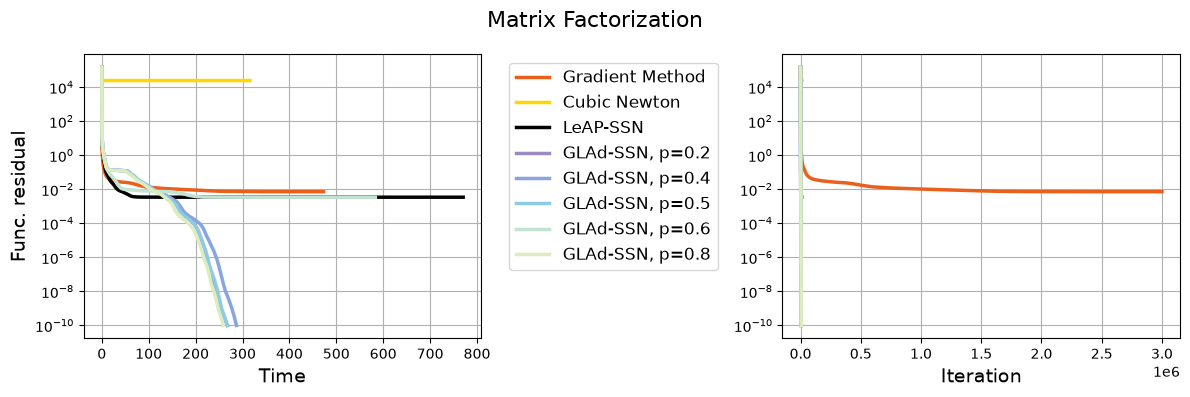

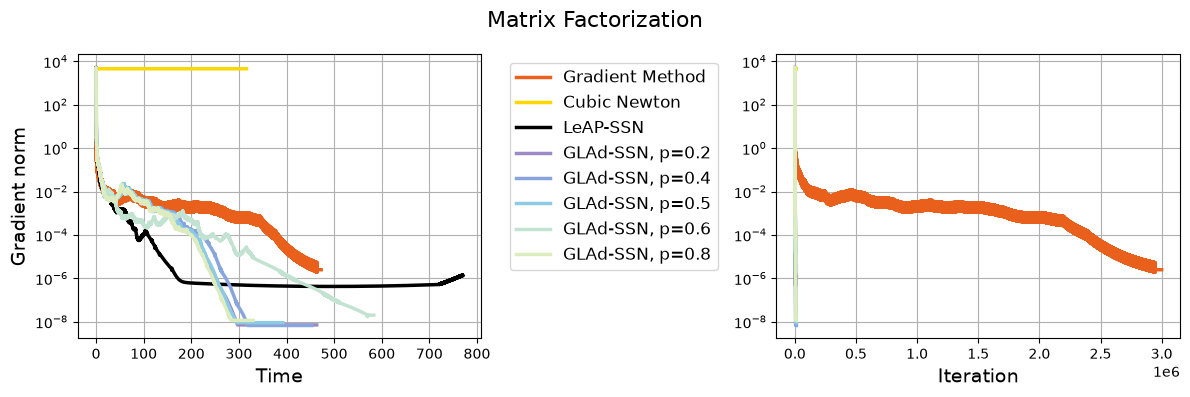

In [16]:
resid = np.array(list(histories.values())[1]["func"])
resid_2 = np.array(list(histories.values())[1]["func_at_lssolve"])


line_widths = [2.5] * len(methods_to_run)
line_styles = ["-"] * len(methods_to_run)

gradient_method_color = "#E8601C"
cubic_newton_color = "gold"
leapssn_color = "black"
gladssn_color = "#9B8AC4"
gladssn_1_color = "#88A5DD"
gladssn_2_color = "#8DCBE4"
gladssn_3_color = "#C2E3D2"
gladssn_4_color = "#DDECBF"
# gladssn_5_color = "#F2E1D0"
colors = [gradient_method_color, cubic_newton_color,leapssn_color, gladssn_color, gladssn_1_color, gladssn_2_color, gladssn_3_color, gladssn_4_color]
marker_cycle = [
"None",   # None Gradient Method
"*",   # star Cubic Newton
"s",   # square LeapSSN
"^",   # triangle up GladSSN
"D",   # diamond GladSSN second
"x",   # x GladSSN third
"v",   # triangle down GladSSN fourth
"h",   # hexagon GladSSN fifth
] 


list_of_mins = [np.min(history["func"]) for history in histories.values()]
mn_func = min(list_of_mins)
plot_figures(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,  # mn_func,
    threshold=1e-10,
    suptitle=("Matrix Factorization"),
    which_measure_2="func",
    max_iter=1000,
)
plot_figures(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=0,
    threshold=1e-10,
    suptitle=("Matrix Factorization"),
    max_iter=1000,
    which_measure_1="grad_norm",
    which_measure_2="grad_norm",
    # which_measure_2="grad_norm_at_lssolve",
    ylabel="Gradient norm",
)

plt.show()

# Plots for the paper

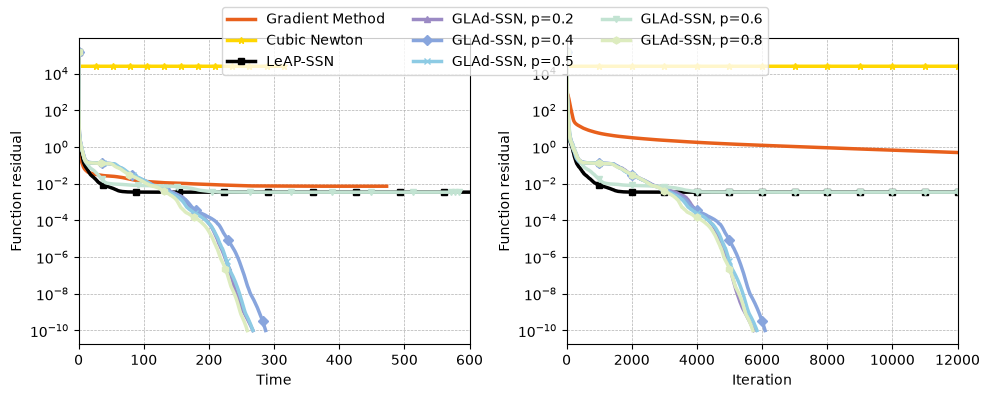

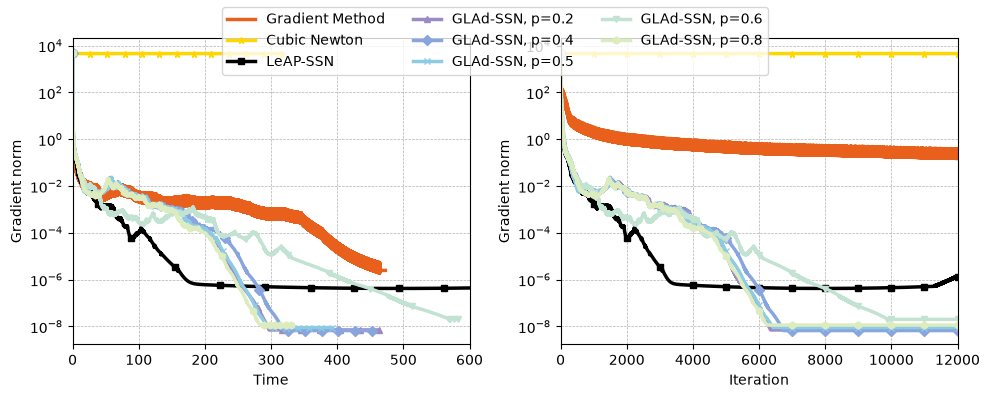

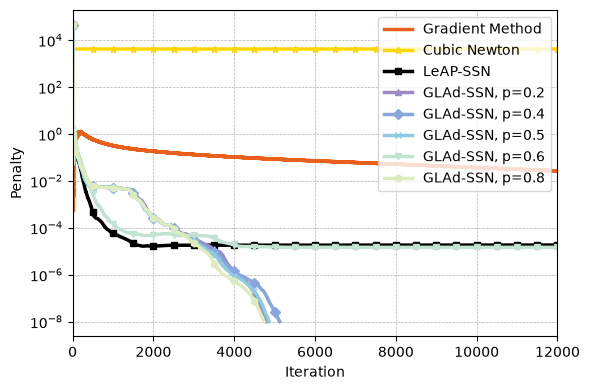

In [17]:
from utils import plot_for_paper_2, plot_for_paper_penalty
markevery_numbers = [50000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

plot_for_paper_2(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Plots"),
    max_iter=12000,
    which_measure="func",
    marker_cycle=marker_cycle,
    markevery_numbers=markevery_numbers,
)
plot_for_paper_2(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Plots"),
    max_iter=12000,
    which_measure="grad_norm",
    marker_cycle=marker_cycle,
    markevery_numbers=markevery_numbers,
)
plot_for_paper_penalty(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    marker_cycle=marker_cycle,
    max_time=12000,
)

In [18]:
# Save only the series used by the MF plots.
import pickle

plot_keys = ("func", "time", "grad_norm", "penalty")
plot_histories = {
    label: {key: np.asarray(history[key]) for key in plot_keys if key in history}
    for label, history in histories.items()
}
with open("mf_results.pkl", "wb") as result_file:
    pickle.dump({"histories": plot_histories, "labels": list(histories)}, result_file)
print("Saved plotting data to mf_results.pkl")

Saved plotting data to mf_results.pkl
